In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
# import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile 
from skophys.viz_helpers import spatial_to_rgba
from skophys.datasets import ARProcess, ARProcessMovie
from tifffile.tifffile import imwrite
from scipy.optimize import curve_fit
import pickle

%matplotlib inline

Unable to find extension: VK_EXT_physical_device_drm


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.13.0) don't match.


In [2]:
from skimage.transform import downscale_local_mean

In [3]:
fig_label = "test"

# fig_label += "_noncentered"
# use_centering = 0 # no centering
# fig_label += "_precentered"
# use_centering = 1 # only center whitening matrix
# fig_label += "_fullcentered"
# use_centering = 2 # center both whitening matrix and data
fig_label += "_filtercentered"
use_centering = 3 # center both whitening matrix and data

fixed_n_components = 10

n_time_windows = 10

# analysis_type = 0 # similarity matching
analysis_type = 1 # covariance matching
# analysis_type = 2 # hybrid matching

# fig_label += "_fitbias"
# fit_bias = True
fig_label += "_nofitbias"
fit_bias = False

fig_label += "_whiten"
use_whitening = True
# fig_label += "_nonwhiten"
# use_whitening = False

fig_label += "_truncated"
truncate_spectrum = True
# fig_label += "_nontruncated"
# truncate_spectrum = False

# denoise_diagonal = True
denoise_diagonal = False

use_eco_init = True
# use_eco_init = False

n_lags = 0
# n_lags = 4
fig_label += f"_{n_lags}lag"


lag_time = 1

In [4]:
# simulation = True
simulation = False

In [5]:
path = "/home/kushal/repos/td-svd-sandbox/demo_movie_mcorr.tiff"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/sue2p.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/1p.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_2.tif"

# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_1.tif"

# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-0_n-clusters-10.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-3_n-clusters-19.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/M19D5_MC_rect-1_n-clusters-19.tif"

# path = "/Users/rshang/Work/fermipy/make_movie_array/raw_gamma_ray_movie.pkl"

In [6]:
def remove_duplicate_rows(matrix):
    matrix = np.array(matrix)
    unique_matrix = np.unique(matrix, axis=1)
    return unique_matrix

In [7]:
if simulation:

    # obs_noise_level = 0.0
    # obs_noise_level = 0.1
    # obs_noise_level = 0.3
    # obs_noise_level = 0.6
    obs_noise_level = 0.9
    # obs_noise_level = 1.2
    ar_noise_sigma = 0.01
    ar_bias = 0.0
    # ar_bias = 5.0
    # bkg_bias = 0.0
    bkg_bias = 2.0
    # bkg_bias = 4.0
    # bkg_bias = 8.0
    # fp = 0.1
    fp = 0.01
    # fp = 0.005
    # rise_constant = 5.
    rise_constant = 2.
    # decay_constant = 0.98
    # decay_constant = 0.95
    # decay_constant = 0.80
    decay_constant = 0.5
    
    random_seed = 6
    np.random.seed(random_seed)

    fig_label += f"_noise{obs_noise_level}"

    sim_time_steps = 1000

    dims = 30, 30
    n_sources = 20
    source_size = 1
    # decay_constant = 0.98
    decay_constant = 0.9

    # dims = 15, 15
    # n_sources = 10
    # source_size = 2
    # decay_constant = 0.6
    
    locs = (np.random.rand(100, 2) * dims[0]).clip(0).astype(int)
    locs = remove_duplicate_rows(locs)
    
    # dims = 20, 20
    # source_size = 2
    # n_sources = 2
    # locs = (np.random.rand(2, 2) * dims[0]).clip(0).astype(int)
    # # locs[0,0] = 6
    # # locs[0,1] = 10
    # # locs[1,0] = 14
    # # locs[1,1] = 10
    # locs[0,0] = 9
    # locs[0,1] = 10
    # locs[1,0] = 10
    # locs[1,1] = 10

if simulation:
    plt.imshow(np.zeros(dims))
    plt.scatter(locs[:, 0], locs[:, 1], c="r")
    plt.show()

In [8]:
if simulation:
    burn_steps = 200
    S = ARProcessMovie(
        n_timepoints=sim_time_steps+burn_steps,
        n_components=n_sources,
        ar_noise_sigma=ar_noise_sigma,
        ar_bias=ar_bias,
        obs_noise_sigma=0.0,
        movie_dims=dims,
        component_size=source_size,
        component_locs=locs,
        rise_constant = rise_constant,
        decay_constant = decay_constant,
        # baselines=[1, 1],
        firing_probability=fp,
        random_seed=random_seed,
    )

    S_obs = ARProcessMovie(
        n_timepoints=sim_time_steps+burn_steps,
        n_components=n_sources,
        ar_noise_sigma=ar_noise_sigma,
        ar_bias=ar_bias,
        obs_noise_sigma=obs_noise_level,
        movie_dims=dims,
        component_size=source_size,
        component_locs=locs,
        rise_constant = rise_constant,
        decay_constant = decay_constant,
        # baselines=[1, 1],
        firing_probability=fp,
        random_seed=random_seed,
    )
    
    B = ARProcessMovie(
        n_timepoints=sim_time_steps+burn_steps,
        n_components=1,
        ar_noise_sigma=0.0,
        ar_bias=bkg_bias,
        obs_noise_sigma=0.0,
        movie_dims=dims,
        component_size=max(int(dims[0]/5),1),
        component_locs=locs,
        rise_constant = rise_constant,
        decay_constant = decay_constant,
        firing_probability=0.,
        random_seed=random_seed,
    )
    
    sns.heatmap(S.kernel, cmap="viridis")
    
    fname = os.path.join(caiman_datadir(), 'example_movies', '/Users/rshang/Work/caiman/mesmerize-core/exp_data/ToySim2D.tif')
    imwrite(fname, S.movie)

In [9]:
if simulation:
    traces = S.traces[:,burn_steps:]
    traces_obs = S_obs.traces_obs[:,burn_steps:]
    
    # fig, ax = plt.subplots(figsize=(6, 3))
    # for src in range(0,len(traces)):
    #     ax.plot(traces[src])
    # ax.axhline(y=0, color='r', linestyle='--')
    # plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_trace_{fig_label}.png')
    # plt.show()
    
    if len(traces)>1:
        n_trace_plot = min(len(traces),5)
        fig, ax = plt.subplots(n_trace_plot, 1, figsize=(10, n_trace_plot))
        for src in range(0,n_trace_plot):
            ax[src].plot(traces[src])
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/trace_truth_{fig_label}.png')
        plt.show()

        fig, ax = plt.subplots(n_trace_plot, 1, figsize=(10, n_trace_plot))
        for src in range(0,n_trace_plot):
            ax[src].plot(traces_obs[src])
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/trace_obs_{fig_label}.png')
        plt.show()

In [10]:
if simulation:
    source_footprints = S.source_footprints
    print (f"source_footprints.shape = {source_footprints.shape}")

In [11]:
if simulation:
    S_movie = S.movie[burn_steps:,:,:]
    B_movie = B.movie[burn_steps:,:,:]
    
    N_movie = obs_noise_level * np.random.randn(S_movie.shape[0], S_movie.shape[1], S_movie.shape[2])
    
    # mid_time_point = int(S_movie.shape[0]/2)
    # N_movie_1 = 0.2 * obs_noise_level * np.random.randn(mid_time_point, S_movie.shape[1], S_movie.shape[2])
    # N_movie_2 = 2. * obs_noise_level * np.random.randn(mid_time_point, S_movie.shape[1], S_movie.shape[2])
    # N_movie = np.vstack((N_movie_1, N_movie_2))
    
    N_movie += obs_noise_level * B_movie * np.random.randn(S_movie.shape[0], S_movie.shape[1], S_movie.shape[2])
    
    # movie = S_movie + N_movie
    movie = S_movie + B_movie + N_movie
    
    # Convert the data type to float32
    S_movie = S_movie.astype(np.float32)
    B_movie = B_movie.astype(np.float32)
    movie = movie.astype(np.float32)
    # movie = movie.astype(np.float32)[:, ::2, ::2]
    print (movie.shape)

In [12]:
if simulation:
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    im = plt.imshow(S_movie.mean(axis=0))
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=1.0)
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_image_truth_{fig_label}.png')

    plt.imshow(B_movie.mean(axis=0))
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/bakcground_image_{fig_label}.png')

In [13]:
from glob import glob

In [14]:
import cv2
import logging
import numpy as np
from scipy.ndimage import convolve, generate_binary_structure
from scipy.sparse import coo_matrix
from typing import Any, Optional

def max_correlation_image(Y, bin_size: int = 1000, eight_neighbours: bool = True, swap_dim: bool = True) -> np.ndarray:
    """Computes the max-correlation image for the input dataset Y with bin_size

    Args:
        Y:  np.ndarray (3D or 4D)
            Input movie data in 3D or 4D format

        bin_size: scalar (integer)
             Length of bin_size (if last bin is smaller than bin_size < 2 bin_size is increased to impose uniform bins)

        eight_neighbours: Boolean
            Use 8 neighbors if true, and 4 if false for 3D data (default = True)
            Use 6 neighbors for 4D data, irrespectively

        swap_dim: Boolean
            True indicates that time is listed in the last axis of Y (matlab format)
            and moves it in the front

    Returns:
        Cn: d1 x d2 [x d3] matrix,
            max correlation image
    """
    logger = logging.getLogger("caiman")

    if swap_dim:
        Y = np.transpose(Y, tuple(np.hstack((Y.ndim - 1, list(range(Y.ndim))[:-1]))))

    T = Y.shape[0]
    if T <= bin_size:
        Cn_bins = local_correlations_fft(Y, eight_neighbours=eight_neighbours, swap_dim=False)
        return Cn_bins
    else:
        if T % bin_size < bin_size / 2.:
            bin_size = T // (T // bin_size)

        n_bins = T // bin_size
        Cn_bins = np.zeros(((n_bins,) + Y.shape[1:]))
        for i in range(n_bins):
            Cn_bins[i] = local_correlations_fft(Y[i * bin_size:(i + 1) * bin_size],
                                                eight_neighbours=eight_neighbours,
                                                swap_dim=False)
            logger.debug(i * bin_size)

        Cn = np.max(Cn_bins, axis=0)
        return Cn


def local_correlations_fft(Y,
                           eight_neighbours: bool = True,
                           swap_dim: bool = True,
                           opencv: bool = True,
                           rolling_window=None) -> np.ndarray:
    """Computes the correlation image for the input dataset Y using a faster FFT based method

    Args:
        Y:  np.ndarray (3D or 4D)
            Input movie data in 3D or 4D format
    
        eight_neighbours: Boolean
            Use 8 neighbors if true, and 4 if false for 3D data (default = True)
            Use 6 neighbors for 4D data, irrespectively
    
        swap_dim: Boolean
            True indicates that time is listed in the last axis of Y (matlab format)
            and moves it in the front
    
        opencv: Boolean
            If True process using OpenCV method

        rolling_window: (undocumented)

    Returns:
        Cn: d1 x d2 [x d3] matrix, cross-correlation with adjacent pixels
    """

    if swap_dim:
        Y = np.transpose(Y, tuple(np.hstack((Y.ndim - 1, list(range(Y.ndim))[:-1]))))

    Y = Y.astype('float32')
    if rolling_window is None:
        Y -= np.mean(Y, axis=0)
        Ystd = np.std(Y, axis=0)
        Ystd[Ystd == 0] = np.inf
        Y /= Ystd
    else:
        Ysum = np.cumsum(Y, axis=0)
        Yrm = (Ysum[rolling_window:] - Ysum[:-rolling_window]) / rolling_window
        Y[:rolling_window] -= Yrm[0]
        Y[rolling_window:] -= Yrm
        del Yrm, Ysum
        Ystd = np.cumsum(Y**2, axis=0)
        Yrst = np.sqrt((Ystd[rolling_window:] - Ystd[:-rolling_window]) / rolling_window)
        Yrst[Yrst == 0] = np.inf
        Y[:rolling_window] /= Yrst[0]
        Y[rolling_window:] /= Yrst
        del Ystd, Yrst

    if Y.ndim == 4:
        if eight_neighbours:
            sz = np.ones((3, 3, 3), dtype='float32')
            sz[1, 1, 1] = 0
        else:
            # yapf: disable
            sz = np.array([[[0, 0, 0], [0, 1, 0], [0, 0, 0]],
                           [[0, 1, 0], [1, 0, 1], [0, 1, 0]],
                           [[0, 0, 0], [0, 1, 0], [0, 0, 0]]],
                          dtype='float32')
            # yapf: enable
    else:
        if eight_neighbours:
            sz = np.ones((3, 3), dtype='float32')
            sz[1, 1] = 0
        else:
            sz = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]], dtype='float32')

    if opencv and Y.ndim == 3:
        Yconv = np.stack([cv2.filter2D(img, -1, sz, borderType=0) for img in Y])
        MASK = cv2.filter2D(np.ones(Y.shape[1:], dtype='float32'), -1, sz, borderType=0)
    else:
        Yconv = convolve(Y, sz[np.newaxis, :], mode='constant')
        MASK = convolve(np.ones(Y.shape[1:], dtype='float32'), sz, mode='constant')

    YYconv = Yconv * Y
    del Y, Yconv
    if rolling_window is None:
        Cn = np.mean(YYconv, axis=0) / MASK
    else:
        YYconv_cs = np.cumsum(YYconv, axis=0)
        del YYconv
        YYconv_rm = (YYconv_cs[rolling_window:] - YYconv_cs[:-rolling_window]) / rolling_window
        del YYconv_cs
        Cn = YYconv_rm / MASK

    return Cn

def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [15]:
movie = tifffile.imread(sorted(glob("/home/kushal/repos/td-svd-sandbox/neurofinder.02.00/images/*.tiff")))
# movie = downscale_local_mean(movie, factors=(1, 4, 4))
movie = movie[:, 256:, 256:]

target_pix_dim = 15
target_time_dim = 2000
image_center_pix_x = int(movie.shape[1]/2)
image_center_pix_y = int(movie.shape[2]/2)

# movie = movie[:target_time_dim, :, :]
# movie = movie[:target_time_dim, ::2, ::2]
# movie = movie[:target_time_dim, image_center_pix_x-target_pix_dim:image_center_pix_x+target_pix_dim, image_center_pix_y-target_pix_dim:image_center_pix_y+target_pix_dim]

# Convert the data type to float32
movie = movie.astype(np.float32)

In [44]:
# N_movie = np.sqrt(B)[None] * np.random.randn(*movie.shape)
N_movie = np.sqrt(np.std(movie, axis=0))[None] * np.random.randn(*movie.shape)
# N_movie = np.random.randn(*movie.shape)

In [45]:
N_movie.shape

(8000, 256, 256)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
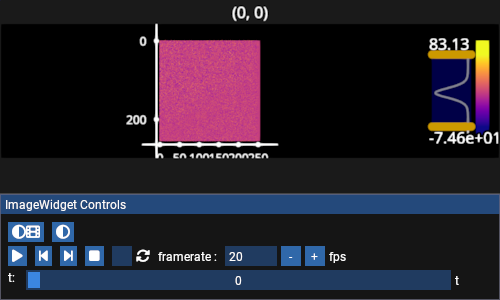

In [46]:
fpl.ImageWidget(N_movie).show()

In [47]:
import imageio
# import imageio.v3 as iio

def convert_matrix_to_gif(movie_matrix, output_filename, fps=1):
    """
    Converts a 3D NumPy array with shape (T, X, Y) into a GIF file.
    """
    # Ensure the data type is uint8, which is expected by imageio for GIFs.
    # If the data is in a different range (e.g., 0.0 to 1.0), it should be
    # scaled to 0-255 before being converted to uint8.
    if movie_matrix.dtype != np.uint8:
        print("Warning: Input data is not of type uint8.")
        print("Scaling data to the 0-255 range and converting to uint8.")
        
        # Normalize to 0-1 range first
        matrix_min = movie_matrix.min()
        matrix_max = movie_matrix.max()
        if matrix_max > matrix_min:
            movie_matrix = (movie_matrix - matrix_min) / (matrix_max - matrix_min)
        else:
            # Handle the case where all values are the same
            movie_matrix = np.zeros_like(movie_matrix)
            
        # Scale to 0-255 and convert type
        movie_matrix = (movie_matrix * 255).astype(np.uint8)

    movie_matrix = movie_matrix[:fps,:,:]
    print (f"movie_matrix.shape = {movie_matrix.shape}")
    # The imageio.mimsave function takes a list of frames (2D arrays)
    # and saves them as a single animated file.
    try:
        print(f"Saving GIF to {output_filename}...")
        # bytes_image = iio.imwrite("<bytes>", movie_matrix, extension=".gif")
        imageio.mimsave(output_filename, movie_matrix, quality=10)
        # Provide the absolute path for clarity on where the file is saved.
        print(f"Successfully saved GIF to: {os.path.abspath(output_filename)}")
    except Exception as e:
        print(f"An error occurred while saving the GIF: {e}")
fps = int(movie.shape[0] / 20)
convert_matrix_to_gif(movie, f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_movie_{fig_label}.gif',fps=fps)

Scaling data to the 0-255 range and converting to uint8.
movie_matrix.shape = (400, 256, 256)
Saving GIF to /Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_movie_test_filtercentered_nofitbias_whiten_truncated_0lag.gif...
An error occurred while saving the GIF: The directory '/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs' does not exist


RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
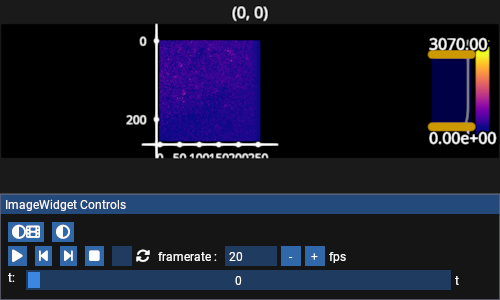

In [48]:
import fastplotlib as fpl
iw_movie = fpl.ImageWidget(movie)
rs = iw_movie.managed_graphics[0]
iw_movie.show()

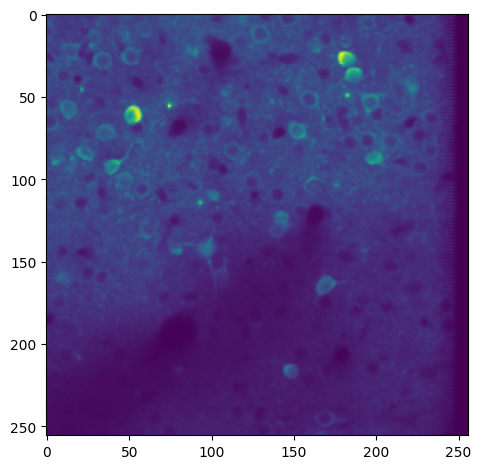

In [49]:
im = plt.imshow(movie.mean(axis=0))
if simulation:
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
plt.tight_layout()

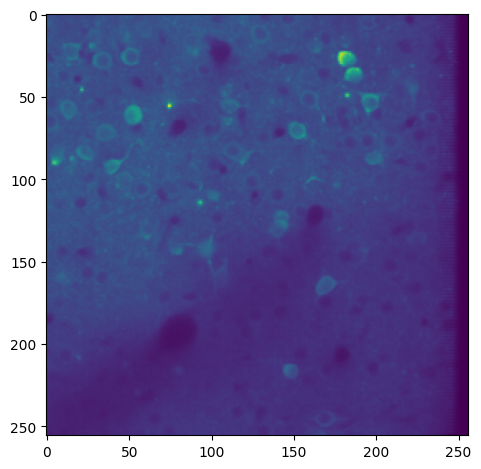

In [50]:
plt.imshow(N_movie.var(axis=0))
plt.tight_layout()
# plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/noise_image_{fig_label}.png')

In [51]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)
Xn = vectorizer.fit_transform(N_movie)

In [52]:
n_pixels = X.shape[0]
n_time_steps = X.shape[1]

print (f"n_pixels = {n_pixels}")
print (f"n_time_steps = {n_time_steps}")

n_pixels = 65536
n_time_steps = 8000


In [53]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eigh(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    T = X.shape[1]
    COV = X @ X.T / float(T)
    
    return COV

def similarity_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[0]
    COV = X.T @ X / float(N)
    
    return COV

def centered_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")
    N = X.shape[0]
    T = X.shape[1]
    
    # X_mean = X.mean(axis=0, keepdims=True) # has a shape of N x 1

    if analysis_type==0:
        ones = np.ones((T,1))
        X_mean = X @ ones @ ones.T / float(T)
        
    else:
        ones = np.ones((N,1))
        X_mean = ones @ ones.T @ X / float(N)
        # ones = np.ones((T,1))
        # X_mean = X @ ones @ ones.T / float(T)
        

    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

def whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    if analysis_type==0:
        
        # COV shape = (N, N)
        COV = covariance_matrix(X0)
        S, U = eigen_decomposition(COV)
    
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
    
        # Epsilon is added to the eigenvalues to prevent division by zero
        epsilon = 1e-5
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        Xw = W @ X
    
        return Xw

    elif analysis_type==1:
        
        # SIM shape = (T, T)
        SIM = similarity_matrix(X0)
        S, U = eigen_decomposition(SIM)
        
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
        
        # Epsilon is added to the eigenvalues to prevent division by zero
        epsilon = 1e-5
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        Xw = X @ W
    
        return Xw

def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def eco_whitened_matrix_T(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (num_extra_rows, k)
    num_extra_rows = X.shape[1] - k
    zeros = np.zeros((num_extra_rows, k))
    
    inv_S_reshape = np.vstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")
    print (f"VT.shape = {VT.shape}")

    # whitening matrix W shape (T, T)
    W = VT.T @ inv_S_reshape

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = X @ W

    return Xw

In [54]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    # print (f"data.shape = {data.shape}")
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids
        

    return labels, centroids

def space_constant_background_estimate(data, n_time_windows=10):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)

    n_classes = 10
    bkg = np.zeros_like(data)
    global_normalized_activity = np.ones(n_pixels)
    global_activity_labels = np.ones(n_pixels)
    data_mean = np.mean(data)
    for win in range(0,n_time_windows):
        data_of_interest = np.sum(data[:,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window],axis=1)/float(n_time_frames_per_window)
        data_of_interest_mean = np.mean(data_of_interest)
        if data_of_interest_mean<0.1*data_mean: continue
        space_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
        global_normalized_activity[:] += space_labels
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)
    cutoff_threshold = global_normalized_mean - 1.5*np.sqrt(global_normalized_var)
    mask = global_normalized_activity < cutoff_threshold
    global_activity_labels[mask] = 0.
    activity_norm = np.sum(global_activity_labels)

    ones = np.ones((n_pixels,1))
    filter_ones = np.ones((n_pixels,1))
    filter_ones[:,0] = global_activity_labels
    bkg = ones @ filter_ones.T @ data / float(activity_norm)

    return bkg

def time_constant_background_estimate(data, n_time_windows=10):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)
    
    # bkg = np.zeros_like(data)
    # for pix in range(0,n_pixels):
    #     for win in range(0,n_time_windows):
    #         data_of_interest = data[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window]
    #         data_of_interest_mean = np.mean(data_of_interest)
    #         data_of_interest_var = np.var(data_of_interest-data_of_interest_mean)
    #         cutoff_threshold = data_of_interest_mean + 2.0*np.sqrt(data_of_interest_var)
    #         mask = data_of_interest >= cutoff_threshold
    #         activity_labels = np.ones_like(data_of_interest)
    #         activity_labels[mask] = 0
    #         activity_norm = np.sum(activity_labels)
    #         bkg_in_pix_win = 0.
    #         if activity_norm>0.:
    #             bkg_in_pix_win = data_of_interest @ activity_labels.T / activity_norm
    #         bkg[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] = bkg_in_pix_win

    n_classes = 10
    bkg = np.zeros_like(data)
    global_normalized_activity = np.ones(n_time_steps)
    global_activity_labels = np.ones(n_time_steps)
    data_mean = np.mean(data)
    for pix in range(0,n_pixels):
        for win in range(0,n_time_windows):
            data_of_interest = data[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window]
            data_of_interest_mean = np.mean(data_of_interest)
            if data_of_interest_mean<0.1*data_mean: continue
            time_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
            global_normalized_activity[win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] += time_labels
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)
    cutoff_threshold = global_normalized_mean - 2.0*np.sqrt(global_normalized_var)
    print (f"cutoff_threshold = {cutoff_threshold}")
    mask = global_normalized_activity < cutoff_threshold
    global_activity_labels[mask] = 0.
    activity_norm = np.sum(global_activity_labels)

    ones = np.ones((n_time_steps,1))
    filter_ones = np.ones((n_time_steps,1))
    filter_ones[:,0] = global_activity_labels
    bkg = data @ filter_ones @ ones.T / float(activity_norm)
    

    return bkg
    

In [55]:
P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pb = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pn = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    for col in range(0,n_time_steps-n_lags*lag_time):
        P[lag,:,col] = X[:,col+lag*lag_time]
        # Pb[lag,:,col] = Xb[:,col+lag*lag_time]
        Pn[lag,:,col] = Xn[:,col+lag*lag_time]
        
print (f"P.shape = {P.shape}")

P.shape = (1, 65536, 8000)


In [56]:
from tqdm import tqdm

In [57]:
def fast_center(X):
    return np.repeat([X.sum(axis=0) / X.shape[0]], X.shape[0], axis=0)

In [58]:
X = P[0]
N = X.shape[0]
T = X.shape[1]

In [59]:
ones = np.ones((N,1))

In [60]:
X.shape

(65536, 8000)

In [61]:
Z0 = []
for lag in range(0,n_lags+1):
    Z0 += [P[lag]]

Zn0 = []
for lag in range(0,n_lags+1):
    Zn0 += [Pn[lag]]

Z0 = np.concatenate(Z0, axis=0)
Zn0 = np.concatenate(Zn0, axis=0)
print (f"Z0.shape = {Z0.shape}")

Z0.shape = (65536, 8000)


In [62]:
Z0Z0T = similarity_matrix(Z0)

In [63]:
Zn0Zn0T = similarity_matrix(Zn0)

In [64]:
S_Z0Z0T, U_Z0Z0T = eigen_decomposition(Z0Z0T)
S_Zn0Zn0T, U_Zn0Zn0T = eigen_decomposition(Zn0Zn0T)

eigenvectors.shape = (8000, 8000)
eigenvectors.shape = (8000, 8000)


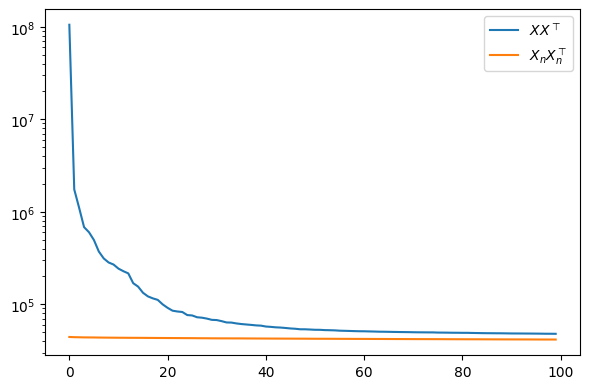

In [65]:
scaling = np.sum((S_Z0Z0T[20:]) / np.sum(S_Zn0Zn0T[20:]))

plot_rank = 100
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(S_Z0Z0T[:plot_rank], label="$XX^{\\top}$")
ax.plot(scaling*S_Zn0Zn0T[:plot_rank], label="$X_{n}X_{n}^{\\top}$")
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
# plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/XXT_spectrum_{fig_label}.png')
plt.show()

In [66]:
nonzero_S = np.array([num for num in S_Z0Z0T if num > np.max(S_Z0Z0T)*1e-6])
nonzero_Sn = np.array([num for num in S_Zn0Zn0T if num > np.max(S_Zn0Zn0T)*1e-6])

In [67]:
import json

In [68]:
coors = list()
with open("/home/kushal/repos/td-svd-sandbox/neurofinder.02.00/regions/regions.json", "r") as f:
    l = json.load(f)
    coors = [np.array(c["coordinates"]) for c in l]

In [69]:
len(coors)

197

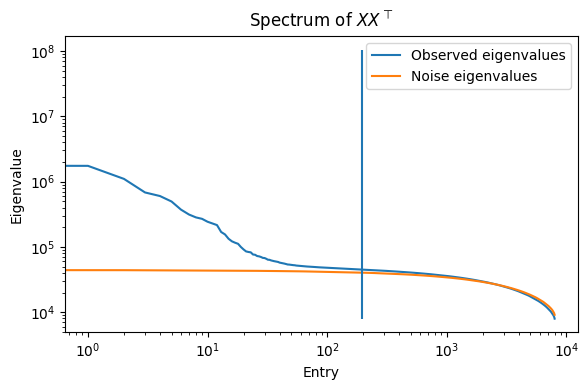

In [70]:
# --- Plot eigenvalue ---
descending_eigvals = np.sort(nonzero_S)[::-1]
descending_noise_eigvals = np.sort(nonzero_Sn)[::-1]

plt.figure(figsize=(6, 4))
plt.plot(descending_eigvals, label="Observed eigenvalues")
plt.plot(scaling * descending_noise_eigvals, label="Noise eigenvalues")
plt.vlines(len(coors), descending_eigvals.min(), descending_eigvals.max())
plt.legend()
plt.title("Spectrum of $XX^{\\top}$")
plt.xlabel("Entry")
plt.ylabel("Eigenvalue")
plt.yscale('log')
plt.xscale('log')
plt.tight_layout()
# plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/XXT_spectrum_{fig_label}.png')
plt.show()

largest noise eigenvalue: 44284.705561917086
lambda_max_bulk_fit = 45362.924133636574


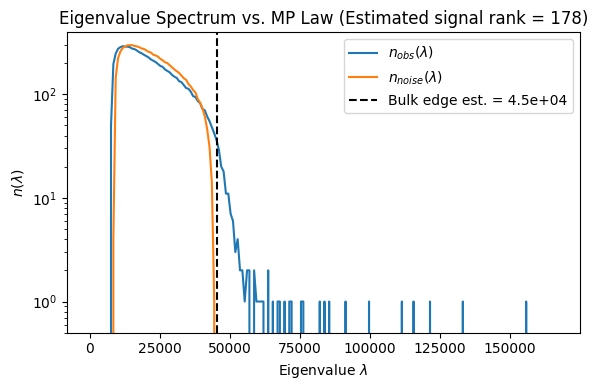

In [71]:
lambda_max_bulk = np.percentile(nonzero_S, 95)  # crude bulk upper estimate
n_bins = 50
x_min_fit = 0.0*lambda_max_bulk
x_max_fit = 1.0*lambda_max_bulk

hist_eigvals, bin_edges = np.histogram(nonzero_S, bins=n_bins, range=(x_min_fit, x_max_fit), density=False)
hist_err_eigvals = np.sqrt(hist_eigvals)
hist_err_eigvals[hist_err_eigvals == 0] = 1 # Set entries equal to 0 to 1

hist_noise_eigvals, bin_edges = np.histogram(scaling * nonzero_Sn, bins=n_bins, range=(x_min_fit, x_max_fit), density=False)

bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

extension_factor = 4.0
n_bins_plt = int(extension_factor*n_bins)
x_min_plt = x_min_fit
x_max_plt = extension_factor * x_max_fit
lam_vals_plt = np.linspace(x_min_plt, x_max_plt, n_bins_plt)

hist_eigvals_plt, bin_edges_plt = np.histogram(nonzero_S, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)
hist_noise_eigvals_plt, bin_edges_plt = np.histogram(scaling * nonzero_Sn, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)

print (f"largest noise eigenvalue: {scaling * descending_noise_eigvals[0]}")

# lambda_max_bulk_fit = scaling * (descending_noise_eigvals[0])
# percentile = 1.0/float(len(nonzero_Sn)) * 100.
# lambda_max_bulk_fit = np.percentile(scaling * nonzero_Sn, 100-percentile)
# lambda_max_bulk_fit += scaling * (descending_noise_eigvals[1] - descending_noise_eigvals[2])
lambda_max_bulk_fit_95 = np.percentile(scaling * nonzero_Sn, 95)
lambda_max_bulk_fit_99 = np.percentile(scaling * nonzero_Sn, 99)
lambda_max_bulk_fit = lambda_max_bulk_fit_95 + 2*(lambda_max_bulk_fit_99-lambda_max_bulk_fit_95)


print (f"lambda_max_bulk_fit = {lambda_max_bulk_fit}")
estimate_rank_signal = np.sum(nonzero_S > lambda_max_bulk_fit)

plt.figure(figsize=(6, 4))
plt.plot(lam_vals_plt, hist_eigvals_plt, label="$n_{obs}(\lambda)$")
plt.plot(lam_vals_plt, hist_noise_eigvals_plt, label="$n_{noise}(\lambda)$")
plt.axvline(lambda_max_bulk_fit, color='k', linestyle='--', label=f"Bulk edge est. = {lambda_max_bulk_fit:0.1e}")
plt.title(f"Eigenvalue Spectrum vs. MP Law (Estimated signal rank = {estimate_rank_signal})")
plt.xlabel("Eigenvalue $\lambda$")
plt.ylabel("$n(\lambda)$")
plt.yscale('log')
# plt.xlim([0, 1.2*lambda_max_bulk_fit])
plt.ylim(bottom=0.5)
plt.legend()
plt.tight_layout()
# plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/MP_fit_{fig_label}.png')
plt.show()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
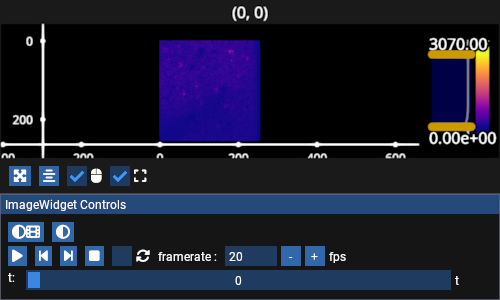

In [72]:
iw_movie.window_funcs = {"t": (np.mean, 11)}
iw_movie.show()

In [81]:
in_sub_fov = 0
for c in coors:
    com = np.mean(c, axis=0)
    if (com[0] > 256) and (com[1] > 256):
        in_sub_fov += 1

In [82]:
in_sub_fov

59

In [74]:
c = (coors[0]).astype(int)

In [78]:
c.mean(axis=0)

array([501.01960784, 424.05882353])

In [531]:
lg = iw_movie.figure[0, 0].add_line(c)

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [532]:
iw_movie.figure[0, 0].delete_graphic(lg)

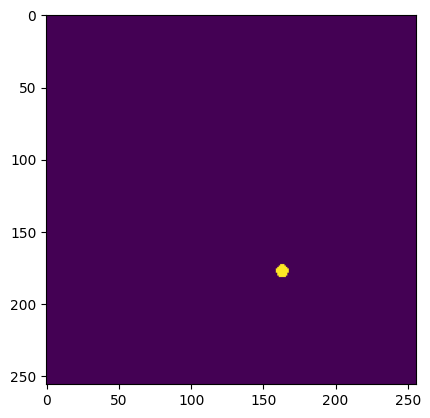

In [533]:
a = np.zeros(movie.shape[1:])
a[c[:, 1], c[:, 0]] = 1
plt.imshow(a)

In [534]:
from scipy.spatial import ConvexHull

In [535]:
def area_to_hull(a: np.ndarray) -> np.ndarray:
    """
    Get the vertices of a convex hull generated from an area represented by a binary mask
    :param a: binary mask
    :return: 2D array of x-y coordinates for the hull vertices
    """
    xs, ys = np.where(a)
    points = np.array((xs, ys)).T
    hull = ConvexHull(points, qhull_options='Qs')
    vs = points[hull.vertices]
    vs = np.vstack([vs, vs[0]])
    return vs

In [538]:
contours = list()
for c in coors:
    a = np.zeros(movie.shape[1:])
    c = (c / 2).astype(int)
    a[c[:, 1], c[:, 0]] = 1
    c = area_to_hull(a)
    g = iw_movie.figure[0, 0].add_line(c, colors="w", thickness=1.0)
    contours.append(g)

In [537]:
for g in contours:
    iw_movie.figure[0, 0].delete_graphic(g)

In [32]:
k = estimate_rank_signal
if fixed_n_components!=0:
    k = fixed_n_components 
if simulation:
    k = n_sources
print (f"k = {k}")

k = 10


In [33]:
Pw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pcw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pw_eco = np.zeros((n_lags+1,k,n_time_steps-n_lags*lag_time))
Pw_eco_T = np.zeros((n_lags+1,n_pixels,k))
for lag in range(0,n_lags+1):
    if use_centering==3:
        Pw_eco[lag,:,:] = eco_whitened_matrix(Pbf[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(Pbf[lag,:,:],Pc[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(Pbf[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    elif use_centering==2:
        Pw_eco[lag,:,:] = eco_whitened_matrix(Pc[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(Pc[lag,:,:],Pc[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(Pc[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    elif use_centering==1:
        Pw_eco[lag,:,:] = eco_whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(P[lag,:,:],Pc[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    elif use_centering==0:
        Pw_eco[lag,:,:] = eco_whitened_matrix(P[lag,:,:],P[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(P[lag,:,:],P[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],k)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")
print (f"Pw_eco.shape = {Pw_eco.shape}")
print (f"Pw_eco_T.shape = {Pw_eco_T.shape}")

X.shape = (1600, 199)
inv_S.shape = (10, 10)
inv_S_reshape.shape = (10, 1600)
W.shape = (10, 1600)
X.shape = (1600, 199)
inv_S.shape = (10, 10)
inv_S_reshape.shape = (199, 10)
VT.shape = (199, 199)
W.shape = (199, 10)
eigenvectors.shape = (199, 199)
eigenvectors.shape = (199, 199)
P.shape = (1, 1600, 199)
Pw.shape = (1, 1600, 199)
Pw_eco.shape = (1, 10, 199)
Pw_eco_T.shape = (1, 1600, 10)


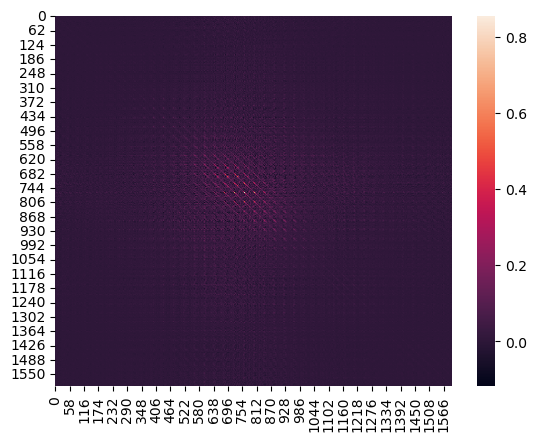

In [34]:
# verify that Pw is whitened data
COV = covariance_matrix(Pw[0,:,:])
sns.heatmap(COV[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/whitened_PTP_{fig_label}.png')

In [35]:
Z = []
Zc = []

if use_whitening:
    for lag in range(0,n_lags+1):
        Z += [Pw[lag]]
        Zc += [Pcw[lag]]
else:
    for lag in range(0,n_lags+1):
        Z += [P[lag]]
        Zc += [Pc[lag]]

Z = np.concatenate(Z, axis=0)
Zc = np.concatenate(Zc, axis=0)

In [36]:
def covariance_weight_matrix(Zx, Zy):
    n_pixels = Zx.shape[0]
    weight_matrix = np.zeros((n_pixels,n_pixels))
    for pix_i in range(0,n_pixels):
        for pix_j in range(0,n_pixels):
            distance = np.sqrt(np.square(Zx[pix_i,0] - Zx[pix_j,0]) + np.square(Zy[pix_i,0] - Zy[pix_j,0]))
            weight_matrix[pix_i,pix_j] = np.exp(-distance*distance/(10*10))
    return weight_matrix

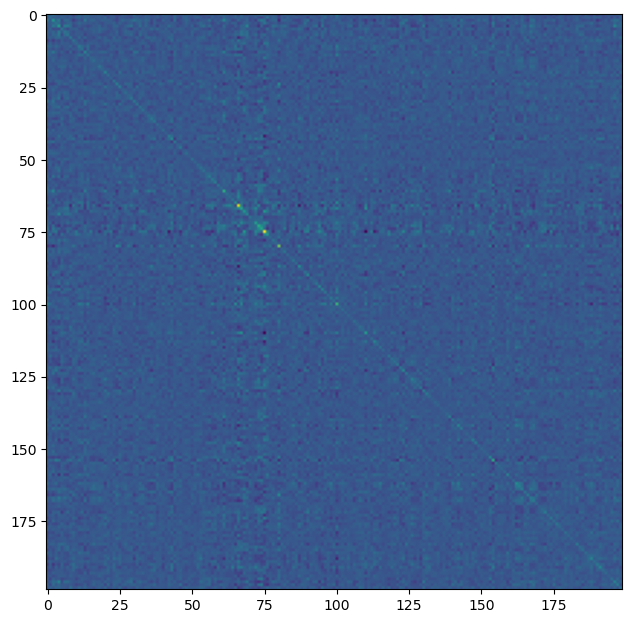

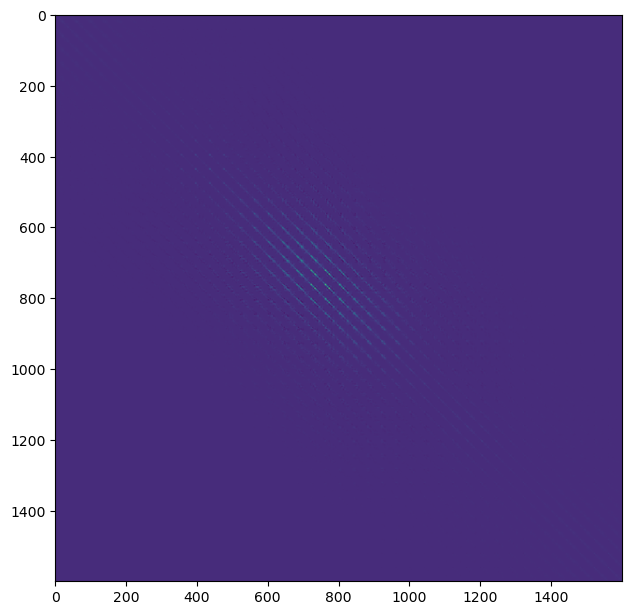

In [37]:
ZTZ = similarity_matrix(Zc)
if not simulation:
    if 'pkl' in path:
        ZZT = covariance_matrix(Zc) * covariance_weight_matrix(Zx, Zy)
    else:
        ZZT = covariance_matrix(Zc)
else:
    ZZT = covariance_matrix(Zc)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZTZ)
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZTZ_{fig_label}.png')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZZT)
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZZT_{fig_label}.png')
plt.show()

In [38]:
from sklearn.utils.extmath import randomized_svd
def nnsvd(X_init, k, eps: float = 1e-6):
    U, S, V = randomized_svd(X_init, n_components=k)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H


H_init.shape = (10, 199)
W_init.shape = (1600, 10)
[[0.00690545 0.00218479 0.00585763 ... 0.00270559 0.00393718 0.00254038]
 [0.00218479 0.00327141 0.00462365 ... 0.00306998 0.00354116 0.00313104]
 [0.00585763 0.00462365 0.01087325 ... 0.00667065 0.00642115 0.00500309]
 ...
 [0.00270559 0.00306998 0.00667065 ... 0.00723502 0.00351592 0.00393808]
 [0.00393718 0.00354116 0.00642115 ... 0.00351592 0.00615874 0.00347315]
 [0.00254038 0.00313104 0.00500309 ... 0.00393808 0.00347315 0.0035142 ]]


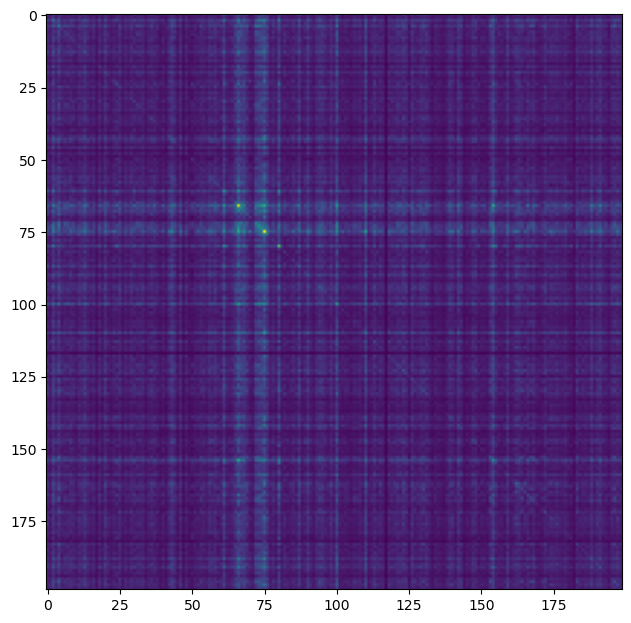

In [39]:
H_init = 2 * np.random.rand(ZTZ.shape[0], k).T
W_init = 2 * np.random.rand(ZZT.shape[0], k)

print (f"H_init.shape = {H_init.shape}")
print (f"W_init.shape = {W_init.shape}")

if use_eco_init:

    # W_init, H_init = nnsvd(Z,k)
    
    H_init = np.zeros((n_time_steps-n_lags*lag_time,k)).T
    W_init = np.zeros(((n_lags+1)*n_pixels,k))
    for lag in range(0,n_lags+1):
        H_init += np.abs(Pw_eco[lag,:,:])
        W_init[lag*n_pixels:(lag+1)*n_pixels,:] += np.abs(Pw_eco_T[lag,:,:])

HTH_init = similarity_matrix(H_init)
print (HTH_init)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(np.abs(HTH_init))
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/HTH_init_{fig_label}.png')
plt.show()

In [40]:
from tqdm.notebook import tqdm

eta = 0.1
error_stop = 1e-4
n_iterations = 5000
error_log = np.zeros(n_iterations)

H = H_init
H = H.clip(0)
W = W_init
W = W.clip(0)

N = Z.shape[0]
T = Z.shape[1]

ones = np.ones((T,1))
RH = np.zeros((k,N))
CH = np.zeros((k,1))
tilde_Z = np.vstack((Zc,ones.T))
inv_tilde_Z = np.linalg.pinv(tilde_Z, rcond=1e-15)

epsilon = 1e-10
epsilon_mtx = np.ones_like(H@H.T@H) * epsilon

beta = 1.0

if analysis_type==0:
    
    for n_iter in tqdm(range(n_iterations)):
        H_old = H.copy()
    
        # gamma = H_old @ ZTZ / (beta * (H_old @ H_old.T @ H_old / float(T)) + epsilon_mtx)
        # H = H_old * (1-eta) + eta * H_old * gamma

        H = H_old + eta * (H_old @ ZTZ - beta * H_old @ H_old.T @ H_old / float(T))
        H = H.clip(0)  
        
        er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
        error_log[n_iter] = er
        # print (f"er = {er}")
    
        if er < error_stop:
            break

    if fit_bias:
        for n_iter in tqdm(range(n_iterations)):
            H_old = H.copy()

            H = H_old + eta * (H_old @ ZTZ - beta * H_old @ H_old.T @ H_old / float(T))
            tilde_RH = H @ inv_tilde_Z

            RH[:,:] = tilde_RH[:,:-1]
            CH[:,:] = -tilde_RH[:,-1:]
            RHZc = RH @ Zc / float(N)
            RHZc = RHZc.clip(0)
            CH = CH.clip(0)
            RH = RHZc @ Zc.T / float(T)
            tilde_RH[:,:-1] = RH[:,:]
            tilde_RH[:,-1:] = -CH[:,:]
            
            H = tilde_RH @ tilde_Z / float(N)

            er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
            error_log[n_iter] = er
            # print (f"er = {er}")
        
            if er < error_stop:
                break

elif analysis_type==1:
    
    for n_iter in tqdm(range(n_iterations)):
        W_old = W.copy() 
    
        W = W_old + eta * (ZZT @ W_old - beta * W_old @ W_old.T @ W_old / float(N))
        W = W.clip(0)
        
        er = np.divide(np.abs(W - W_old), np.abs(W_old + epsilon)).mean() / eta
        error_log[n_iter] = er
        # print (f"er = {er}")
    
        if er < error_stop:
            break

  0%|          | 0/5000 [00:00<?, ?it/s]

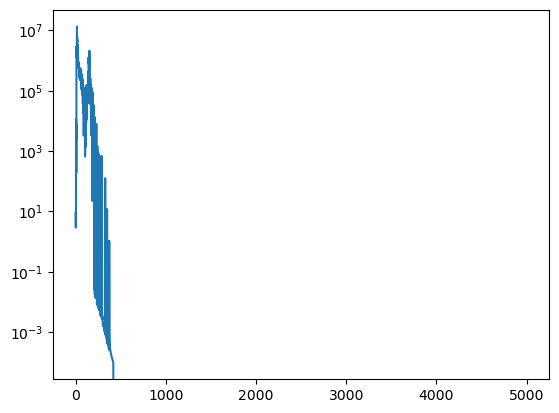

In [41]:
plt.plot(error_log)
plt.yscale('log')
# plt.xscale('log')
plt.show()

[[1.81754047e-04 1.46414953e-04 1.15144163e-04 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.46414953e-04 1.17947652e-04 9.27727522e-05 ... 4.96532411e-10
  0.00000000e+00 0.00000000e+00]
 [1.15144163e-04 9.27727522e-05 7.33560582e-05 ... 1.24163794e-08
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 4.96532411e-10 1.24163794e-08 ... 2.46258383e-09
  3.67217010e-11 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 3.67217010e-11
  3.44554600e-09 1.15869509e-08]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  1.15869509e-08 4.08461540e-08]]


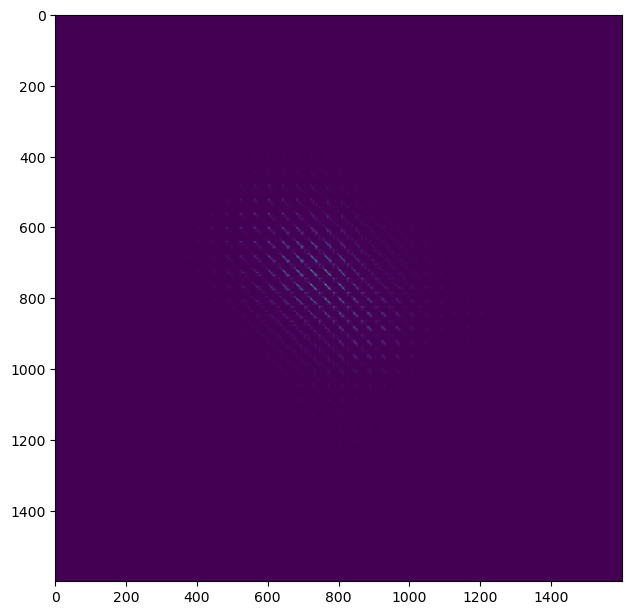

In [42]:
if analysis_type==0:
    HTH = similarity_matrix(H)
    print (HTH)
    
    fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
    ax.imshow(np.abs(HTH))
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/HTH_{fig_label}.png')
    plt.show()
else:
    WWT = covariance_matrix(W)
    print (WWT)
    
    fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
    ax.imshow(np.abs(WWT[:n_pixels,n_lags*n_pixels:]))
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/WWT_{fig_label}.png')
    plt.show()

In [43]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity

def permute_rows_to_maximize_trace(A):
    """
    Permute the rows of a square matrix A to maximize the trace of the resulting matrix.
    
    Parameters:
        A (numpy.ndarray): Square matrix of shape (n, n)
        
    Returns:
        A_permuted (numpy.ndarray): Matrix with permuted rows
        permutation (numpy.ndarray): The optimal row permutation
        max_trace (float): The maximum trace achieved
    """
    # Convert maximization to minimization by negating the matrix
    cost_matrix = -A
    row_indices, col_indices = linear_sum_assignment(cost_matrix)

    # Apply the optimal row permutation
    A_permuted = A[:, col_indices]
    max_trace = np.trace(A_permuted)
    
    return A_permuted, row_indices, col_indices, max_trace

def sort_solutions(H, H_ref):

    M_cossim = cosine_similarity(H, H_ref)
    print (f"M_cossim.shape = {M_cossim.shape}")
    M_cossim_permute, row_indices, col_indices, _ = permute_rows_to_maximize_trace(M_cossim)
    print (f"row_indices = {row_indices}")
    print (f"col_indices = {col_indices}")

    H_sorted = H[col_indices, :]
    
    return H_sorted

In [44]:
if analysis_type==0:
    H = sort_solutions(H, H_init)
else:
    WT = sort_solutions(W.T, W_init.T)
    W = WT.T

M_cossim.shape = (10, 10)
row_indices = [0 1 2 3 4 5 6 7 8 9]
col_indices = [7 9 2 3 4 5 1 8 6 0]


In [45]:
# Zs = Z0
# Zs = Z
Zs = Zc
if analysis_type==0:

    if not fit_bias:
        A_concatenated = Zc @ H.T
        S_solved_by_sim = A_concatenated.T @ Zs
        # S_solved_by_sim = H
    else:
        S_solved_by_sim = RH @ Zs
        A_concatenated = RH.T
    print (f"A_concatenated.shape = {A_concatenated.shape}")
    
    A_solved_by_sim = np.zeros((n_pixels,k))
    if n_lags==0:
        A_solved_by_sim += A_concatenated
    else:
        for lag in range(0,n_lags+1):
            A_solved_by_sim[:,:] += A_concatenated[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
    
    S_solved_by_sim = S_solved_by_sim.clip(0)
    A_solved_by_sim = A_solved_by_sim.clip(0)
    
    image_array_by_sim = []
    for entry in range(0,k):
        snapshot = unvec.transform(A_solved_by_sim[:,entry])
        image_array_by_sim += [snapshot]

else:

    A_solved_by_cov = np.zeros((n_pixels,k))
    if n_lags==0:
        A_solved_by_cov += W
    else:
        for lag in range(0,n_lags+1):
            A_solved_by_cov[:,:] += W[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
    S_solved_by_cov = W.T @ Zs
    
    S_solved_by_cov = S_solved_by_cov.clip(0)
    A_solved_by_cov = A_solved_by_cov.clip(0)
    
    image_array_by_cov = []
    for entry in range(0,k):
        snapshot = unvec.transform(A_solved_by_cov[:,entry])
        image_array_by_cov += [snapshot]
        

In [46]:
if simulation:

    truth_vec = vectorizer.fit_transform(source_footprints).T
    # truth_vec = traces_filtercentered
    print (f"truth_vec.shape = {truth_vec.shape}")

    if analysis_type==0:
        cluster_matching_by_sim = []
        selected_cluster_by_sim = []
        for src in range(0,n_sources):
            max_corr = 0.
            pair_indices = [src,src]
            for cluster in range(0,k):
                if cluster in selected_cluster_by_sim: 
                    continue
                corr = truth_vec[src] @ A_solved_by_sim[:,cluster].T / np.sqrt(1e-5 + A_solved_by_sim[:,cluster] @ A_solved_by_sim[:,cluster].T * truth_vec[src] @ truth_vec[src].T)
                # corr = truth_vec[src].T @ S_solved_by_sim[cluster,:] / np.sqrt(1e-5 + S_solved_by_sim[cluster,:].T @ S_solved_by_sim[cluster,:] * truth_vec[src].T @ truth_vec[src])
                if corr >= max_corr:
                    max_corr = corr
                    pair_indices = [src, cluster]
            cluster_matching_by_sim += [pair_indices]
            selected_cluster_by_sim += [pair_indices[1]]
        print (f"cluster_matching = {cluster_matching_by_sim}")

    if analysis_type==1:
        cluster_matching_by_cov = []
        selected_cluster_by_cov = []
        for src in range(0,n_sources):
            max_corr = 0.
            pair_indices = []
            for cluster in range(0,k):
                if cluster in selected_cluster_by_cov: 
                    continue
                corr = truth_vec[src] @ A_solved_by_cov[:,cluster].T / np.sqrt(1e-5 + A_solved_by_cov[:,cluster] @ A_solved_by_cov[:,cluster].T * truth_vec[src] @ truth_vec[src].T)
                # corr = truth_vec[src].T @ S_solved_by_cov[cluster,:] / np.sqrt(1e-5 + S_solved_by_cov[cluster,:].T @ S_solved_by_cov[cluster,:] * truth_vec[src].T @ truth_vec[src])
                if corr >= max_corr:
                    max_corr = corr
                    pair_indices = [src, cluster]
            cluster_matching_by_cov += [pair_indices]
            selected_cluster_by_cov += [pair_indices[1]]
        print (f"cluster_matching = {cluster_matching_by_cov}")


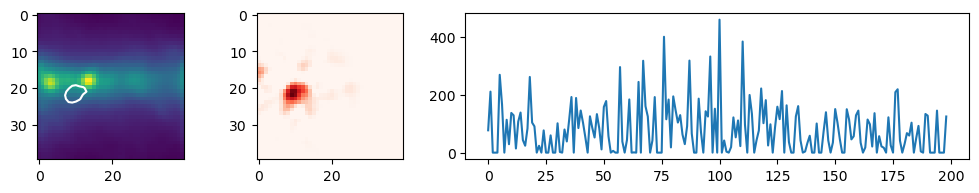

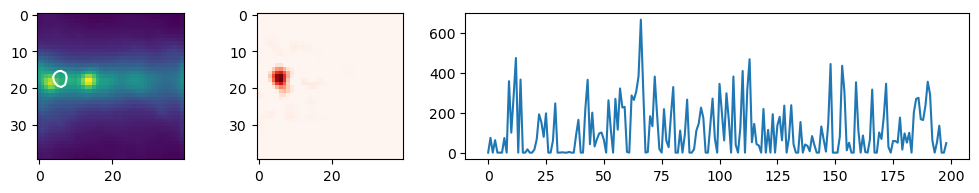

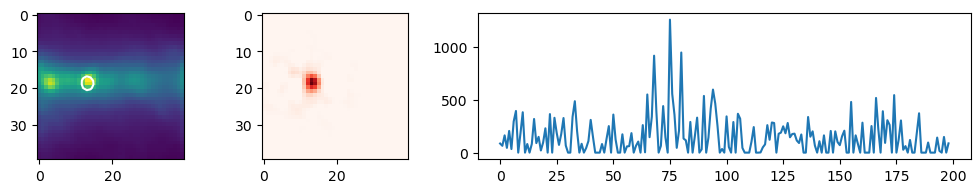

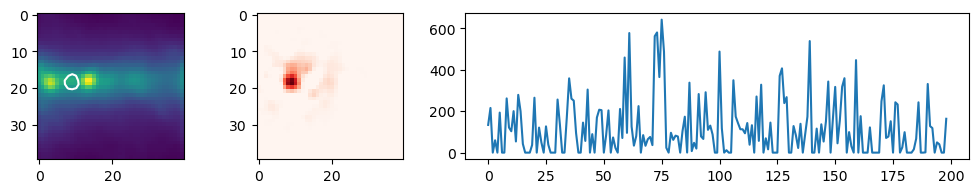

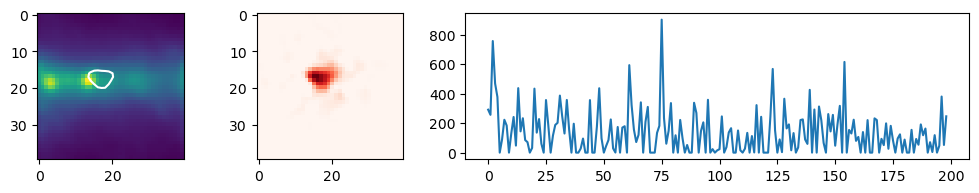

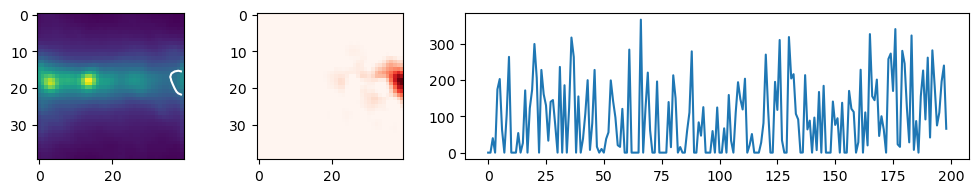

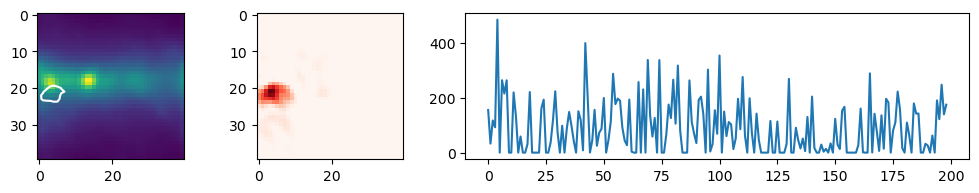

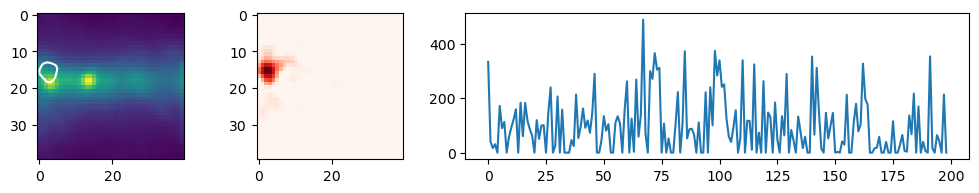

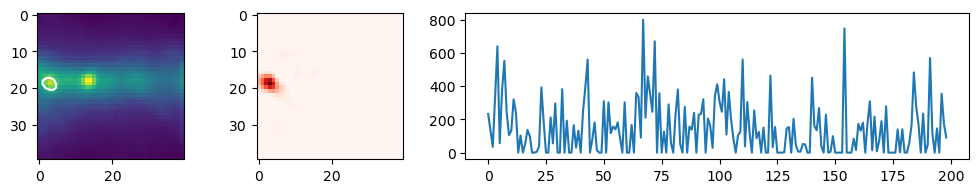

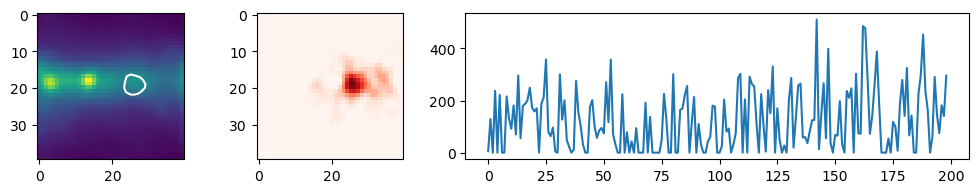

In [47]:
if analysis_type==0:

    matching_score = 0.
    truth_score = 0.
    if simulation:
        reco_levels = [0.60]
        for src in range(0,n_sources):
            truth_levels = [0.60]
            fig, ax = plt.subplots(2, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 3]})
            cluster = cluster_matching_by_sim[src][1]
            reco_levels = [0.30*np.max(image_array_by_sim[cluster])]
            ax[0][0].imshow(movie.mean(axis=0))
            ax[0][0].contour(source_footprints[src], levels=truth_levels, colors='r')
            # ax[0][0].contour(image_array_by_sim[cluster] / np.max(image_array_by_sim[cluster]), levels=reco_levels, colors='w')
            ax[1][0].imshow(image_array_by_sim[cluster], cmap="Reds")
            ax[1][1].plot(S_solved_by_sim[cluster], label="reconstruction")
            ax[0][1].plot(traces[src], label="truth", color="orange")
            # ax[2].legend()
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_sim_{fig_label}.png')
            plt.show()
    
            matching_score += S_solved_by_sim[cluster].T @ traces[src,n_lags*lag_time:]
            truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved_by_sim[cluster].T @ S_solved_by_sim[cluster])
    
        print (f"matching_score / truth_score = {matching_score / truth_score}")
    else:
        for src in range(0,k):
            reco_levels = [0.30*np.max(image_array_by_sim[src])]
            fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
            ax[0].imshow(movie.mean(axis=0))
            ax[0].contour(image_array_by_sim[src], levels=reco_levels, colors='w')
            ax[1].imshow(image_array_by_sim[src], cmap="Reds")
            ax[2].plot(S_solved_by_sim[src])
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_sim_{fig_label}.png')
            plt.show()

else:

    matching_score = 0.
    truth_score = 0.
    if simulation:
        reco_levels = [0.60]
        for src in range(0,n_sources):
            truth_levels = [0.60]
            reco_levels = [0.60*np.max(image_array_by_cov[cluster])]
            fig, ax = plt.subplots(2, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 3]})
            cluster = cluster_matching_by_cov[src][1]
            ax[0][0].imshow(movie.mean(axis=0))
            ax[0][0].contour(source_footprints[src], levels=truth_levels, colors='r')
            # ax[0][0].contour(image_array_by_cov[cluster] / np.max(image_array_by_cov[cluster]), levels=reco_levels, colors='w')
            ax[1][0].imshow(image_array_by_cov[cluster], cmap="Reds")
            ax[1][1].plot(S_solved_by_cov[cluster], label="reconstruction")
            ax[0][1].plot(traces[src], label="truth", color="orange")
            # ax[2].legend()
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_cov_{fig_label}.png')
            plt.show()
    
            matching_score += S_solved_by_cov[cluster].T @ traces[src,n_lags*lag_time:]
            truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved_by_cov[cluster].T @ S_solved_by_cov[cluster])
    
        print (f"matching_score / truth_score = {matching_score / truth_score}")
    else:
        for src in range(0,k):
            reco_levels = [0.50*np.max(image_array_by_cov[src])]
            fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
            ax[0].imshow(movie.mean(axis=0))
            ax[0].contour(image_array_by_cov[src], levels=reco_levels, colors='w')
            ax[1].imshow(image_array_by_cov[src], cmap="Reds")
            ax[2].plot(S_solved_by_cov[src])
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_cov_{fig_label}.png')
            plt.show()

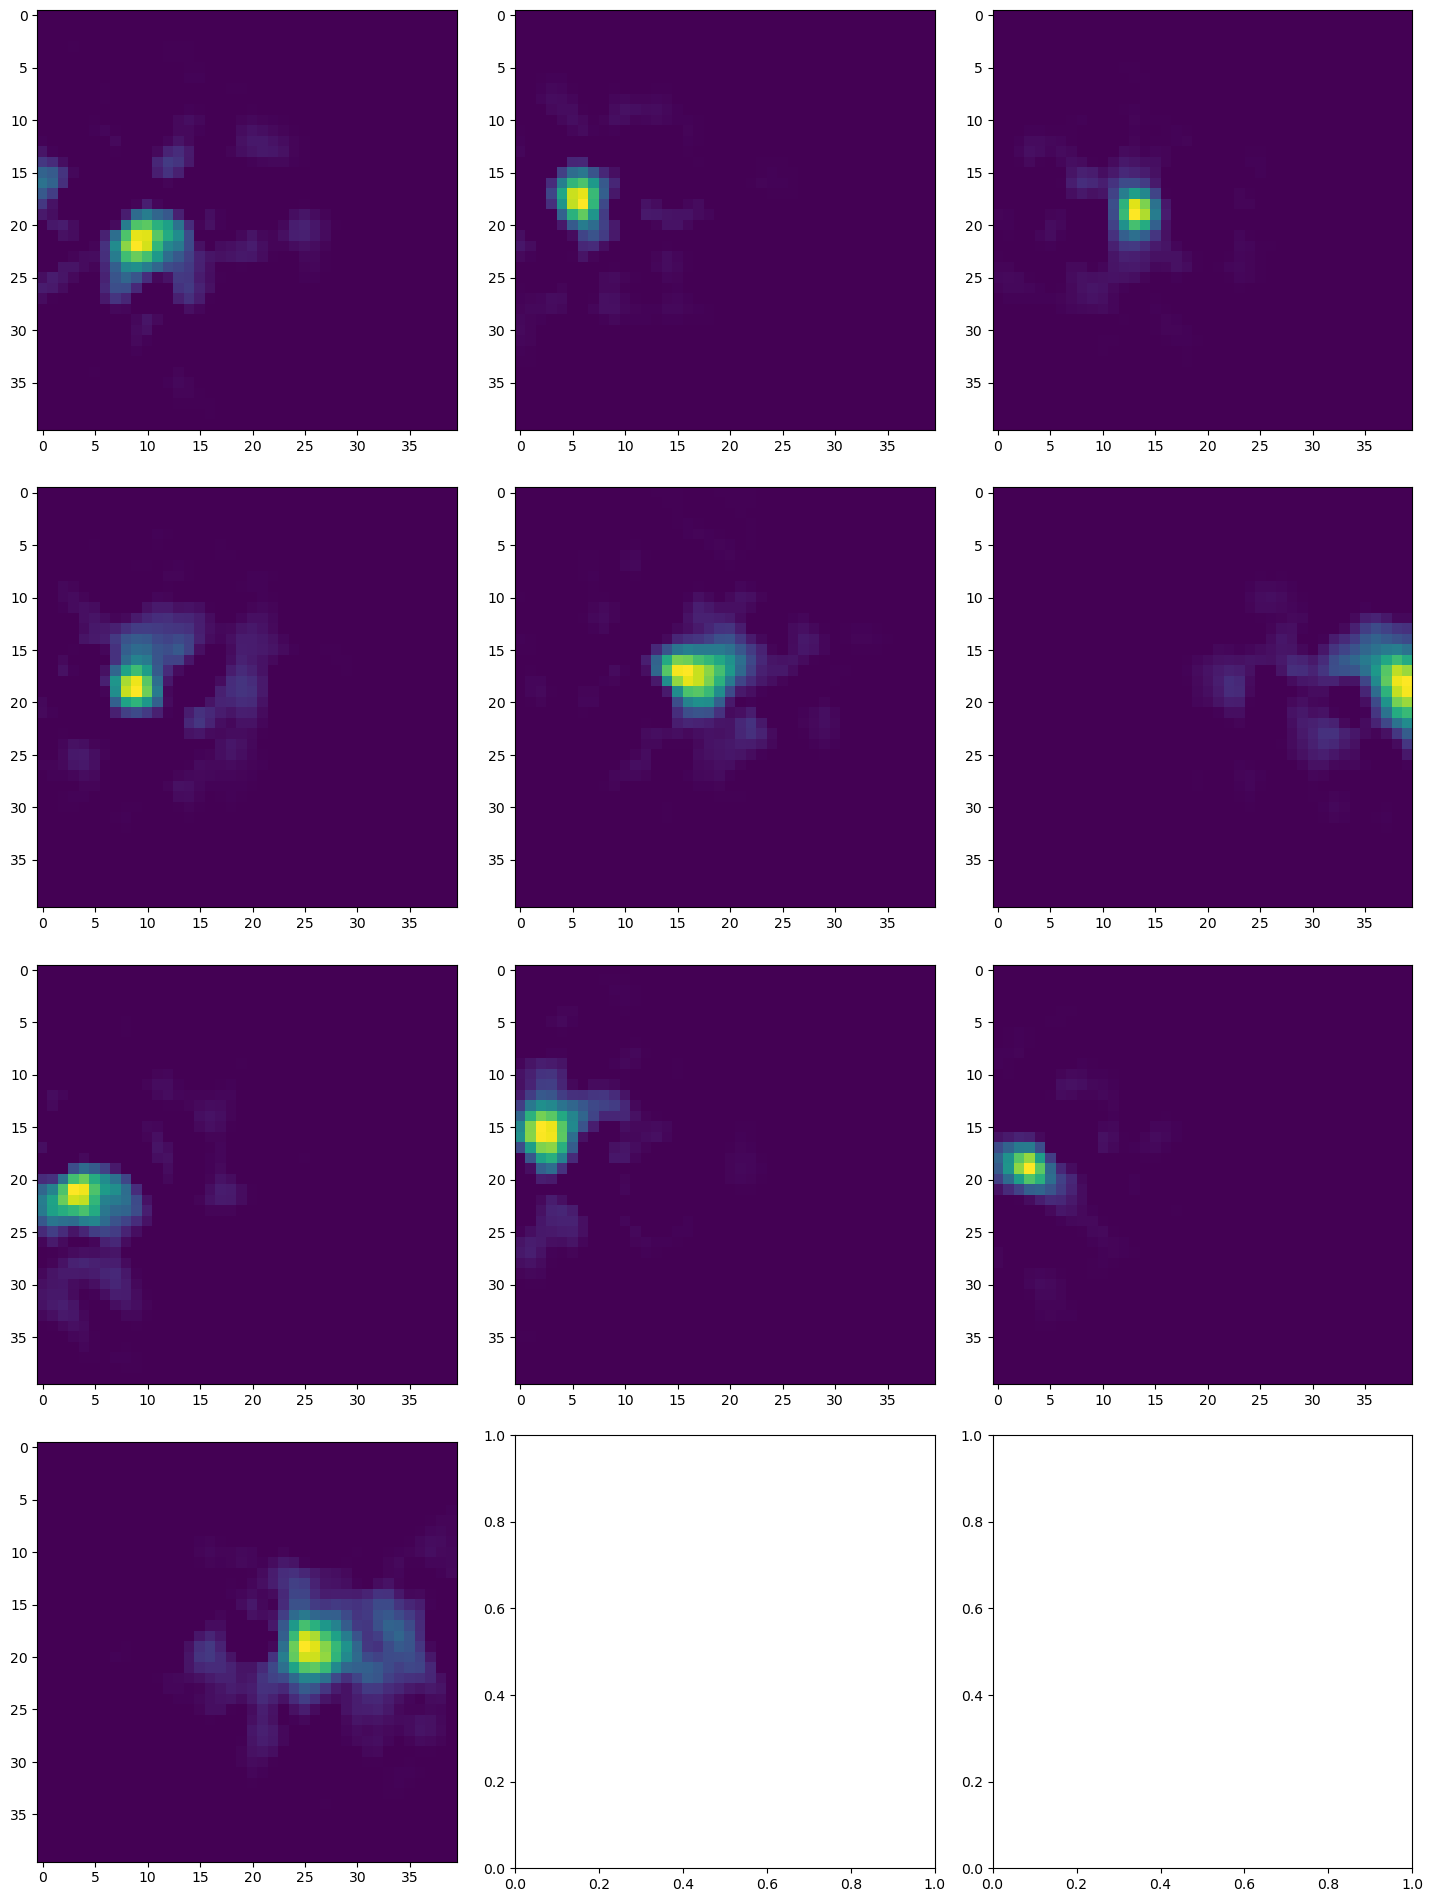

In [48]:
n_row = int(np.sqrt(k))
n_col = int(k/n_row)
if k>n_row*n_col:
    n_row += 1
if n_row==1:
    n_row += 1
if n_col==1:
    n_col += 1
fig, ax = plt.subplots(n_row, n_col, figsize=(n_col * 4.8, n_row * 4.8))
entry = 0
for row in range(0,n_row):
    for col in range(0,n_col):
        if entry>=k: continue
        if analysis_type==0:
            ax[row][col].imshow(image_array_by_sim[entry])
        else:
            ax[row][col].imshow(image_array_by_cov[entry])
        entry += 1
plt.tight_layout()
if analysis_type==0:
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_footprint_by_sim_{fig_label}.png')
else:
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_footprint_by_cov_{fig_label}.png')
plt.show()

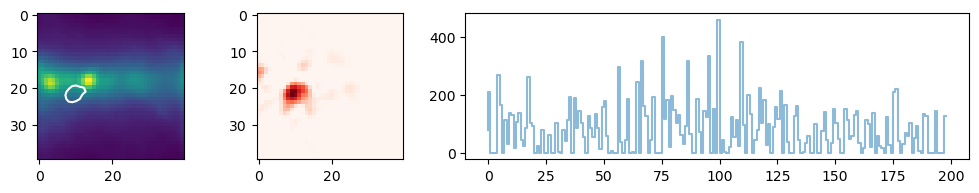

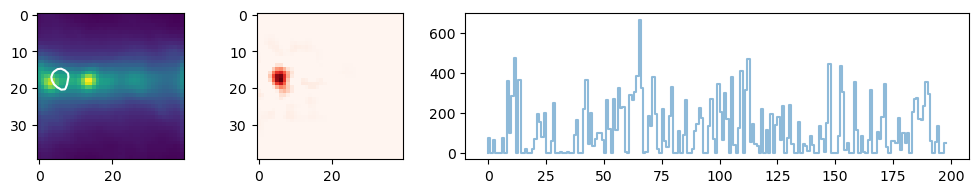

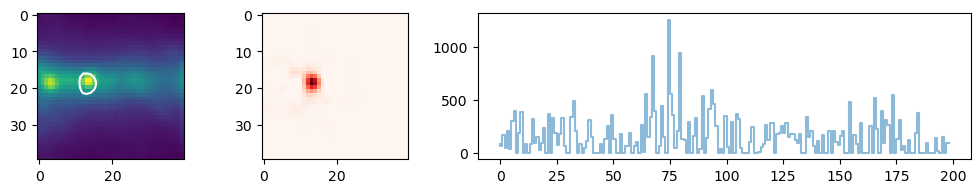

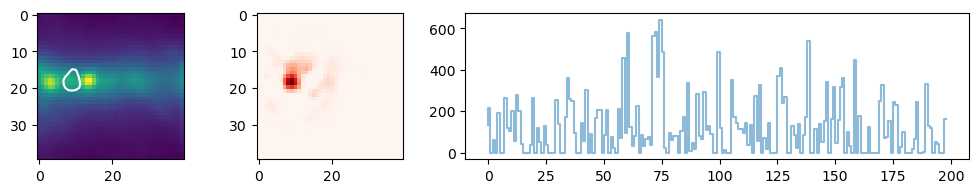

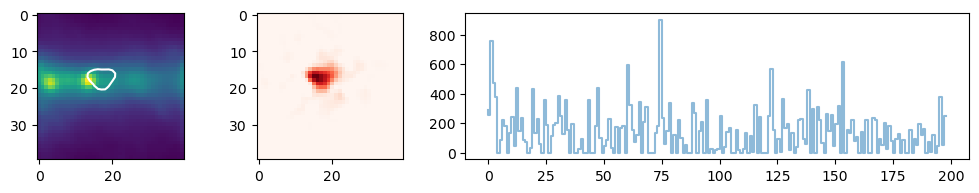

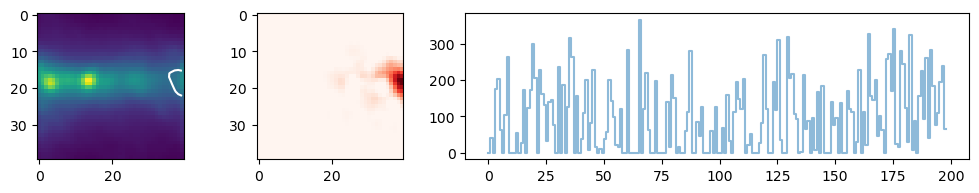

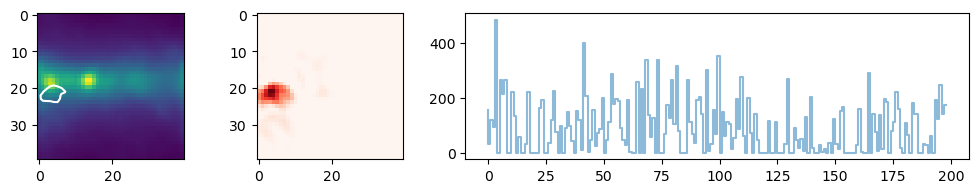

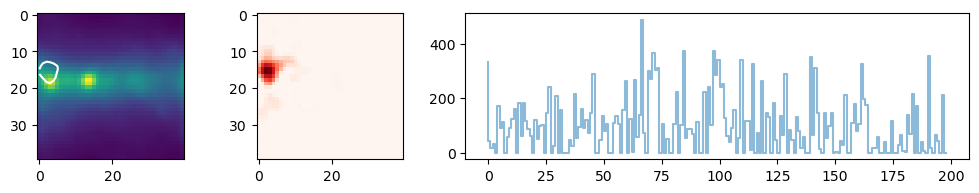

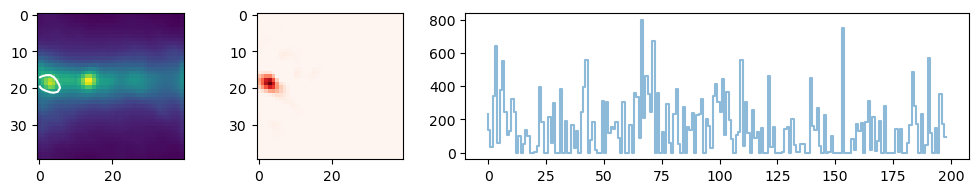

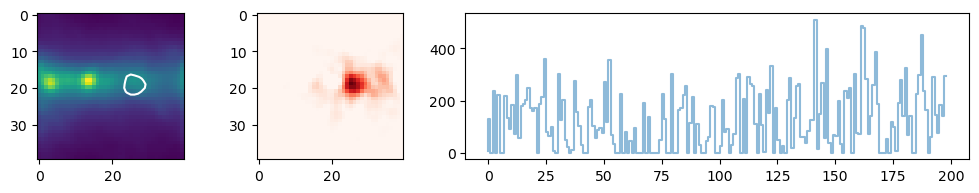

In [49]:
if not simulation:
    if "pkl" in path:
        n_time_frames_per_window = int(n_time_steps/n_energy_bins)
        if analysis_type==0:
            reco_levels = [0.50*np.max(image_array_by_sim[src])]
            for src in range(0,k):
                fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
                for tw in range(0,n_energy_bins):
                    ax[0].imshow(movie.mean(axis=0))
                    ax[0].contour(image_array_by_sim[src], levels=reco_levels, colors='w')
                    ax[1].imshow(image_array_by_sim[src], cmap="Reds")
                    S = S_solved_by_sim[src][tw*n_time_frames_per_window:(tw+1)*n_time_frames_per_window]
                    S_norm = np.sum(S)
                    ax[2].plot(S, drawstyle='steps', alpha=0.5)
                plt.tight_layout()
                plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/energy_lightcurve_src{src}_by_sim_{fig_label}.png')
                plt.show()
        elif analysis_type==1:
            reco_levels = [0.50*np.max(image_array_by_cov[src])]
            for src in range(0,k):
                fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
                for tw in range(0,n_energy_bins):
                    ax[0].imshow(movie.mean(axis=0))
                    ax[0].contour(image_array_by_cov[src], levels=reco_levels, colors='w')
                    ax[1].imshow(image_array_by_cov[src], cmap="Reds")
                    S = S_solved_by_cov[src][tw*n_time_frames_per_window:(tw+1)*n_time_frames_per_window]
                    S_norm = np.sum(S)
                    ax[2].plot(S, drawstyle='steps', alpha=0.5)
                plt.tight_layout()
                plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/energy_lightcurve_src{src}_by_cov_{fig_label}.png')
                plt.show()

In [50]:
if simulation:
    if analysis_type==0:
        M_cossim = cosine_similarity(S_solved_by_sim, traces[:,:n_time_steps-n_lags*lag_time])
        M_cossim_permute, _, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
        print (f"max_trace = {max_trace/M_cossim.shape[0]}")
        
        fig, ax = plt.subplots(1, 1, figsize=(5, 5))
        im = ax.imshow(M_cossim_permute)
        cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
        plt.xlabel("Extracted source index")
        plt.ylabel("Truth source index")
        plt.title(f"Average cosine similarity {max_trace/M_cossim.shape[0]:0.2f}")
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_cos_similarity_by_sim_{fig_label}.png')
        plt.show()

In [51]:
if simulation:
    if analysis_type==1:
        M_cossim = cosine_similarity(S_solved_by_cov, traces[:,:n_time_steps-n_lags*lag_time])
        M_cossim_permute, _, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
        print (f"max_trace = {max_trace/M_cossim.shape[0]}")

        fig, ax = plt.subplots(1, 1, figsize=(5, 5))
        im = ax.imshow(M_cossim_permute)
        cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
        plt.xlabel("Extracted source index")
        plt.ylabel("Truth source index")
        plt.title(f"Average cosine similarity {max_trace/M_cossim.shape[0]:0.2f}")
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_cos_similarity_by_cov_{fig_label}.png')
        plt.show()
        

In [52]:
if analysis_type==0:
    M_cossim = cosine_similarity(S_solved_by_sim, S_solved_by_sim)
    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim)
    M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    print (f"M_cossim_meanoff = {M_cossim_meanoff}")
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(M_cossim)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/S_cos_similarity_by_sim_{fig_label}.png')
    plt.show()
    
    M_cossim = cosine_similarity(A_solved_by_sim.T, A_solved_by_sim.T)
    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim)
    M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    print (f"M_cossim_meanoff = {M_cossim_meanoff}")
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(M_cossim)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/A_cos_similarity_by_sim_{fig_label}.png')
    plt.show()


M_cossim_meanoff = 0.4463396826500841


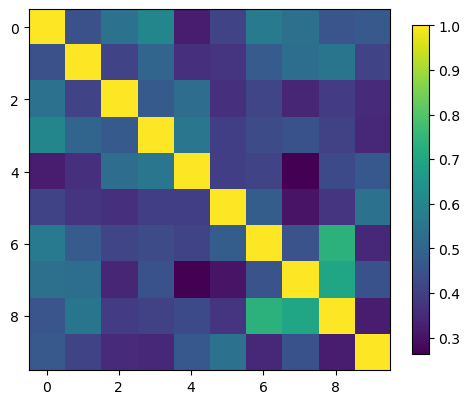

M_cossim_meanoff = 0.08171165887976167


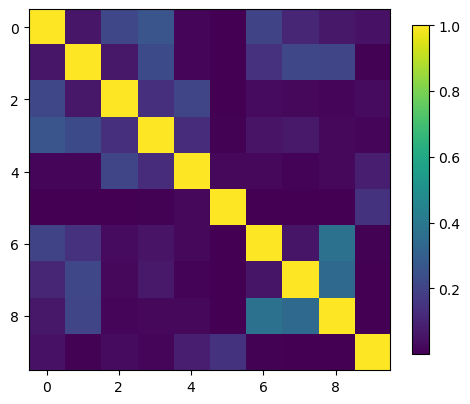

In [53]:
if analysis_type==1:
    M_cossim = cosine_similarity(S_solved_by_cov, S_solved_by_cov)
    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim)
    M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    print (f"M_cossim_meanoff = {M_cossim_meanoff}")
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(M_cossim)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/S_cos_similarity_by_cov_{fig_label}.png')
    plt.show()

    
    M_cossim = cosine_similarity(A_solved_by_cov.T, A_solved_by_cov.T)
    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim)
    M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    print (f"M_cossim_meanoff = {M_cossim_meanoff}")
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(M_cossim)
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/A_cos_similarity_by_cov_{fig_label}.png')
    plt.show()
    

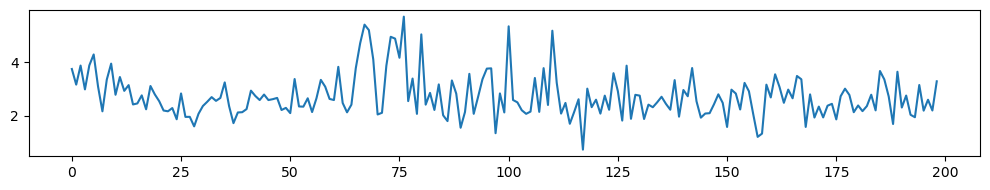

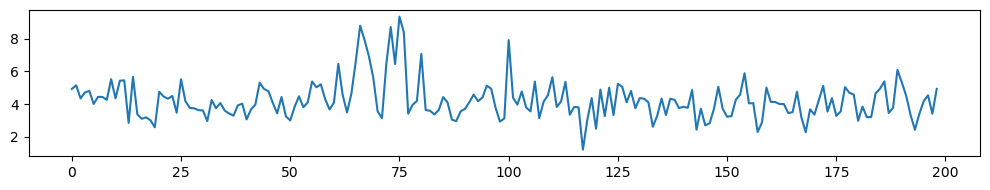

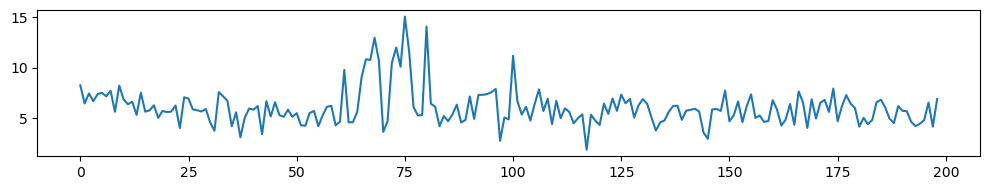

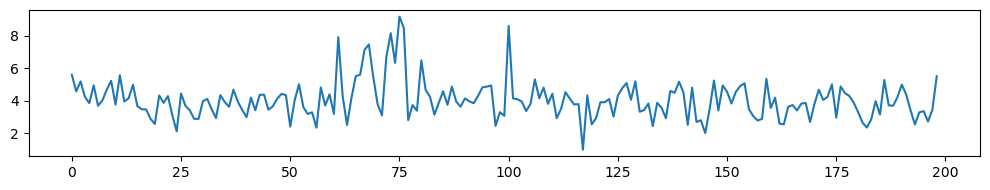

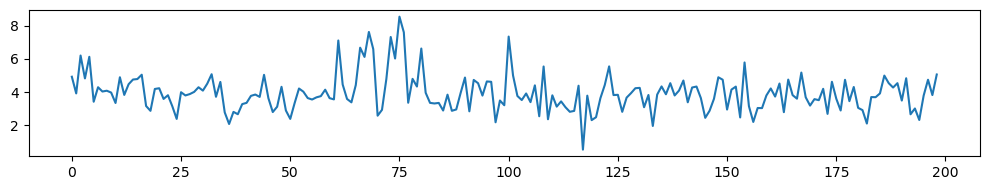

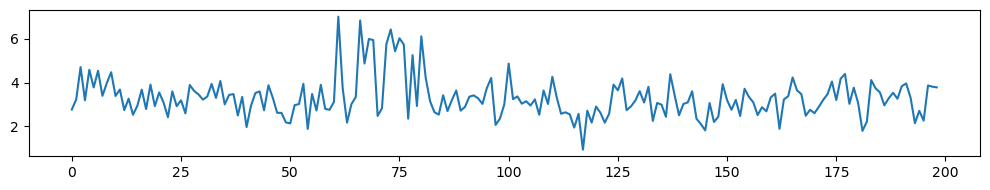

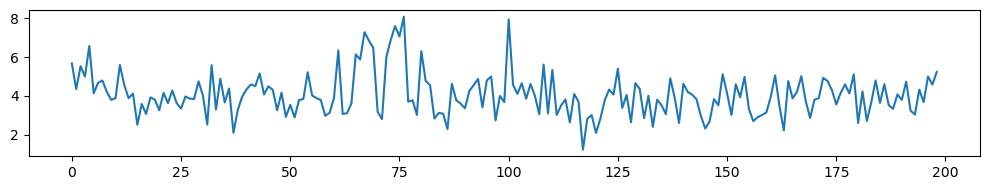

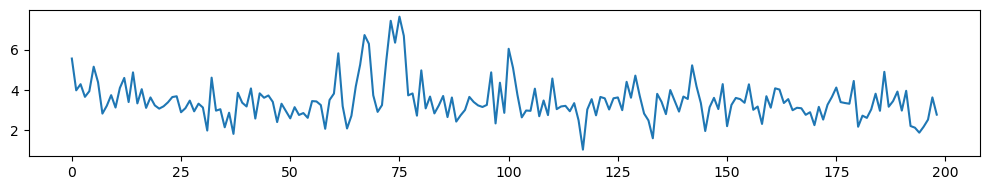

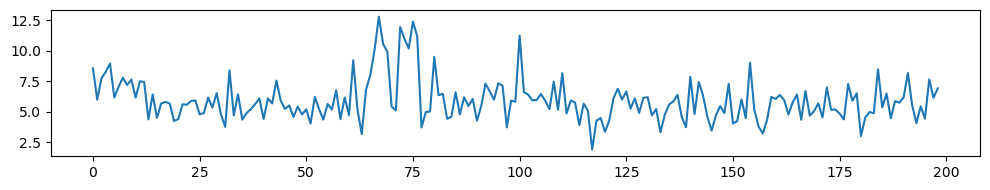

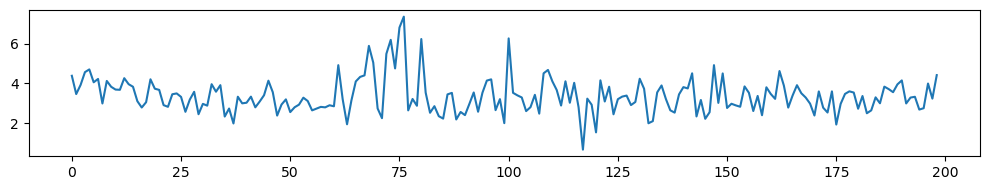

In [54]:
selected_sources = [1, 2]
for src in range(0,k):
    if analysis_type==0:
        sorted_indices = np.argsort(A_solved_by_sim[:,src])
    else:
        sorted_indices = np.argsort(A_solved_by_cov[:,src])
    for pix in range(0,1):
        fig, ax = plt.subplots(figsize=(10, 2))
        ax.plot(X[sorted_indices[-pix-1]][:])
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/random_trace_src{src}_pix{pix}_{fig_label}.png')
        plt.show()